In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Grafiklerin kaydedileceği klasörü oluşturma
os.makedirs("../reports/figures", exist_ok=True)

# Veriyi yükleme ve ilk 5 satırı gösterme
df = pd.read_csv("../data/raw/credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# Kredi Riski Tahmini (Credit Risk Prediction) Bitirme Projesi

## İş Problemi
Kredi başvurusunda bulunan müşterilerin demografik ve finansal bilgilerine bakarak krediyi geri ödeyememe (temerrüde düşme) riskini tahmin eden bir makine öğrenmesi modeli geliştirmektir. Temel hedefimiz, yüksek riskli başvuruları önceden tespit ederek finansal kurumun kredi zararlarını azaltmaktır.

## Veri Kaynağı ve Kısıtlamalar
Veri seti Kaggle platformundan açık kaynak olarak temin edilen credit_risk_dataset.csv dosyasıdır. Veri seti 11 bağımsız özellik (yaş, gelir, ev sahipliği, çalışma süresi, kredi amacı, kredi notu, kredi tutarı, faiz oranı, gelir-kredi oranı, geçmiş temerrüt durumu, kredi geçmişi uzunluğu) ve 1 hedef değişkenden (loan_status) oluşmaktadır. Gerçek zamanlı makroekonomik verileri içermemesi ve bazı sütunlarda hatalı/eksik girişler barındırması veri setinin kısıtlarıdır.

## Başarı Kriteri
Projenin iş başarısı, temerrüde düşecek riskli müşterilerin gözden kaçırılmaması (yüksek Recall) ve buna bağlı olarak batık kredi oranının düşürülmesidir.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


## Veri Seti Genel Yapısı ve İlk Gözlemler
Veri setinde toplam 12 sütun bulunmaktadır. Bunların 8 tanesi sayısal, 4 tanesi ise kategorik tiptedir. Yapılan kontrolde person_emp_length (çalışma süresi) ve loan_int_rate (faiz oranı) sütunlarında eksik değerler (null) olduğu tespit edilmiştir.

In [3]:
# Eksik değerlerin sayısını görme
print("--- Eksik Değer Sayıları ---")
print(df.isnull().sum())

# Sayısal sütunların istatistiksel özeti
df.describe()

--- Eksik Değer Sayıları ---
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


## Eksik Veri ve İstatistiksel Özet Bulguları
Eksik değer kontrolü sonucunda yalnızca person_emp_length ve loan_int_rate sütunlarında boş değerler bulunduğu doğrulanmıştır. İstatistiksel özet tablosu (describe) incelendiğinde ise person_age (yaş) sütununda 144 gibi biyolojik olarak imkansız değerler ve person_emp_length (çalışma süresi) sütununda 123 yıl gibi hatalı aykırı girişler olduğu tespit edilmiştir.

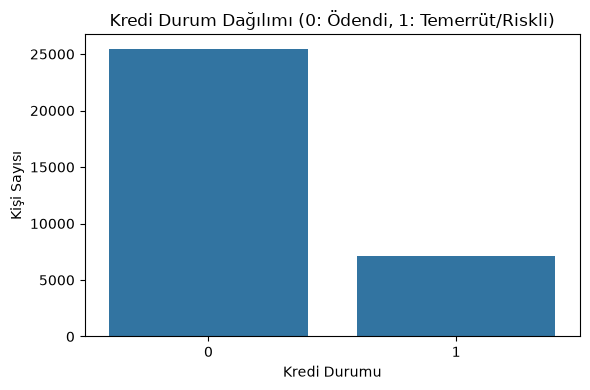

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(x='loan_status', data=df)
plt.title('Kredi Durum Dağılımı (0: Ödendi, 1: Temerrüt/Riskli)')
plt.xlabel('Kredi Durumu')
plt.ylabel('Kişi Sayısı')
plt.tight_layout()
plt.savefig('../reports/figures/loan_status_distribution.png', dpi=300)
plt.show()

## Kredi Durum Dağılımı Grafiği Yorumu
Grafik incelendiğinde veri setindeki müşterilerin büyük çoğunluğunun (yaklaşık %78, 25.000'in üzerinde kişi) kredisini sorunsuz ödediği (0), yaklaşık %22'lik kısmının (7.000 civarı kişi) ise temerrüde düştüğü (1) görülmektedir. Bu sınıf dengesizliği (class imbalance), model değerlendirme aşamasında tek başına Accuracy metriğinin yanıltıcı olacağını ve F1-Score ile Recall metriklerinin kullanılması gerektiğini göstermiştir.

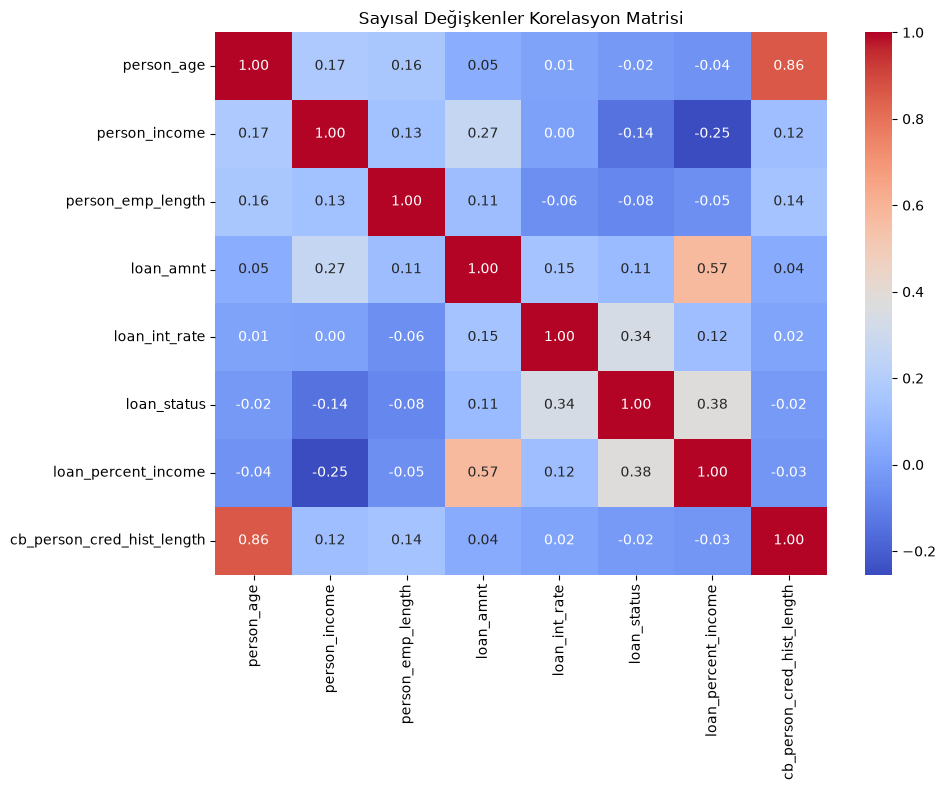

In [5]:
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Sayısal Değişkenler Korelasyon Matrisi')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=300)
plt.show()

## Kişisel Yıllık Gelir Dağılımı Grafiği Yorumu
Grafik incelendiğinde müşterilerin yıllık gelir dağılımının sağa çarpık (right-skewed) bir yapıya sahip olduğu görülmektedir. Başvuruların büyük çoğunluğu 30.000 ile 80.000 aralığında yoğunlaşırken, 150.000 ve üzerindeki yüksek gelirli müşteri sayısı oldukça azdır.

## Sayısal Değişkenler Korelasyon Matrisi Yorumu
Hedef değişken olan kredi temerrüt durumu (loan_status) ile en güçlü pozitif ilişkiye sahip özellikler 0.38 ile gelir-kredi oranı (loan_percent_income) ve 0.34 ile kredi faiz oranıdır (loan_int_rate). Kişisel yıllık gelir (person_income) ile temerrüt arasında ise -0.14 ile negatif bir ilişki vardır; yani gelir arttıkça ödeyememe riski düşmektedir. Bağımsız değişkenler arasında müşteri yaşı (person_age) ile kredi geçmişi uzunluğu (cb_person_cred_hist_length) arasında 0.86 gibi çok yüksek bir pozitif korelasyon tespit edilmiştir.

## Projenin Zayıf Yönleri
Veri seti geçmiş dönem başvurularını içermektedir ve enflasyon veya faiz değişimleri gibi güncel makroekonomik koşulları yansıtmamaktadır. Ayrıca kredi ödeyen ve temerrüde düşen sınıflar arasında dengesizlik bulunması modelin azınlık sınıfını öğrenmesini zorlaştırmaktadır.

## Gelecek Çalışmalar
1 ay daha zaman olsaydı sınıf dengesizliğini gidermek için SMOTE gibi veri artırma teknikleri uygulanır, XGBoost veya LightGBM gibi daha gelişmiş modeller denenir ve FastAPI ile anlık kredi skoru hesaplayan bir servis oluşturulurdu.